In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

df = pd.read_csv(ROOT / "data/raw/heart_disease.csv")

df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [8]:
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nDuplicate records:", df.duplicated().sum())

df.describe(include="all").T

Dataset shape: (920, 16)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB

Duplicate records: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,920.0,NaN,NaN,NaN,460.5,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,NaN,NaN,NaN,53.51087,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920,2,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,920,4,Cleveland,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,920,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,861.0,NaN,NaN,NaN,132.132404,19.06607,0.0,120.0,130.0,140.0,200.0
chol,890.0,NaN,NaN,NaN,199.130337,110.78081,0.0,175.0,223.0,268.0,603.0
fbs,830,2,False,692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,918,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,865.0,NaN,NaN,NaN,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0


,Missing Count,Missing Percentage
ca,611,66.413043
thal,486,52.826087
slope,309,33.586957
fbs,90,9.782609
oldpeak,62,6.739130
trestbps,59,6.413043
thalch,55,5.978261
exang,55,5.978261
chol,30,3.260870
restecg,2,0.217391


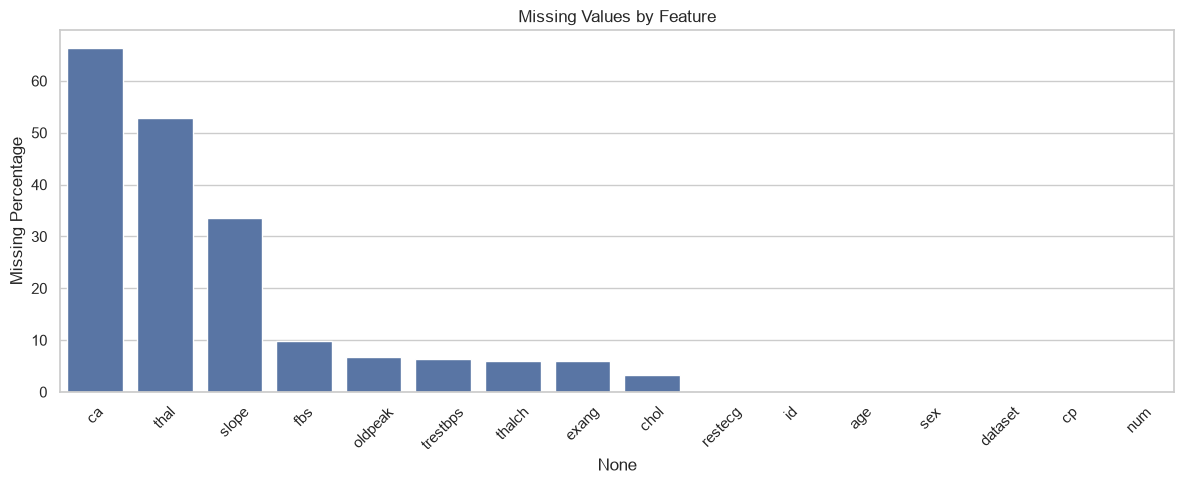

In [9]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=missing.index,
    y=missing["Missing Percentage"]
)

plt.xticks(rotation=45)
plt.title("Missing Values by Feature")
plt.ylabel("Missing Percentage")
plt.tight_layout()
plt.show()

In [11]:
medical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalch"
]

for column in medical_columns:
    print(
        column,
        "| Zero values:", (df[column] == 0).sum(),
        "| Negative values:", (df[column] < 0).sum()
    )

age | Zero values: 0 | Negative values: 0
trestbps | Zero values: 1 | Negative values: 0
chol | Zero values: 172 | Negative values: 0
thalch | Zero values: 0 | Negative values: 0


In [12]:
categorical_columns = [
    "sex", "cp", "fbs",
    "restecg", "exang",
    "slope", "ca", "thal",
    "num"
]

for column in categorical_columns:
    print(column, ":", df[column].unique())

sex : <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
cp : <ArrowStringArray>
['typical angina', 'asymptomatic', 'non-anginal', 'atypical angina']
Length: 4, dtype: str
fbs : [True False nan]
restecg : <ArrowStringArray>
['lv hypertrophy', 'normal', 'st-t abnormality', nan]
Length: 4, dtype: str
exang : [False True nan]
slope : <ArrowStringArray>
['downsloping', 'flat', 'upsloping', nan]
Length: 4, dtype: str
ca : [ 0.  3.  2.  1. nan]
thal : <ArrowStringArray>
['fixed defect', 'normal', 'reversable defect', nan]
Length: 4, dtype: str
num : [0 2 1 3 4]


target
1    509
0    411
Name: count, dtype: int64
target
1    55.326087
0    44.673913
Name: proportion, dtype: float64


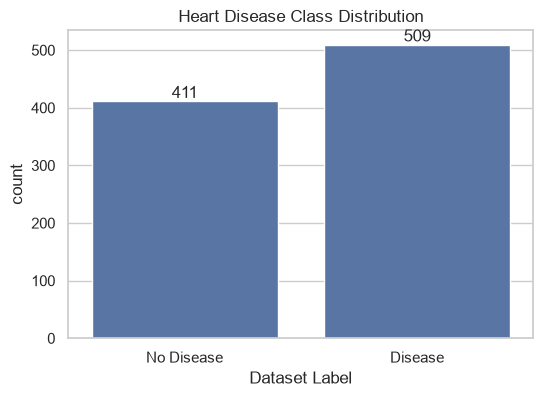

In [13]:
df["target"] = df["num"].map({
    0: 0,
    1: 1,
    2: 1,
    3: 1,
    4: 1
})

print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))

ax = sns.countplot(data=df, x="target")

ax.bar_label(ax.containers[0])

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.title("Heart Disease Class Distribution")
plt.xlabel("Dataset Label")
plt.show()

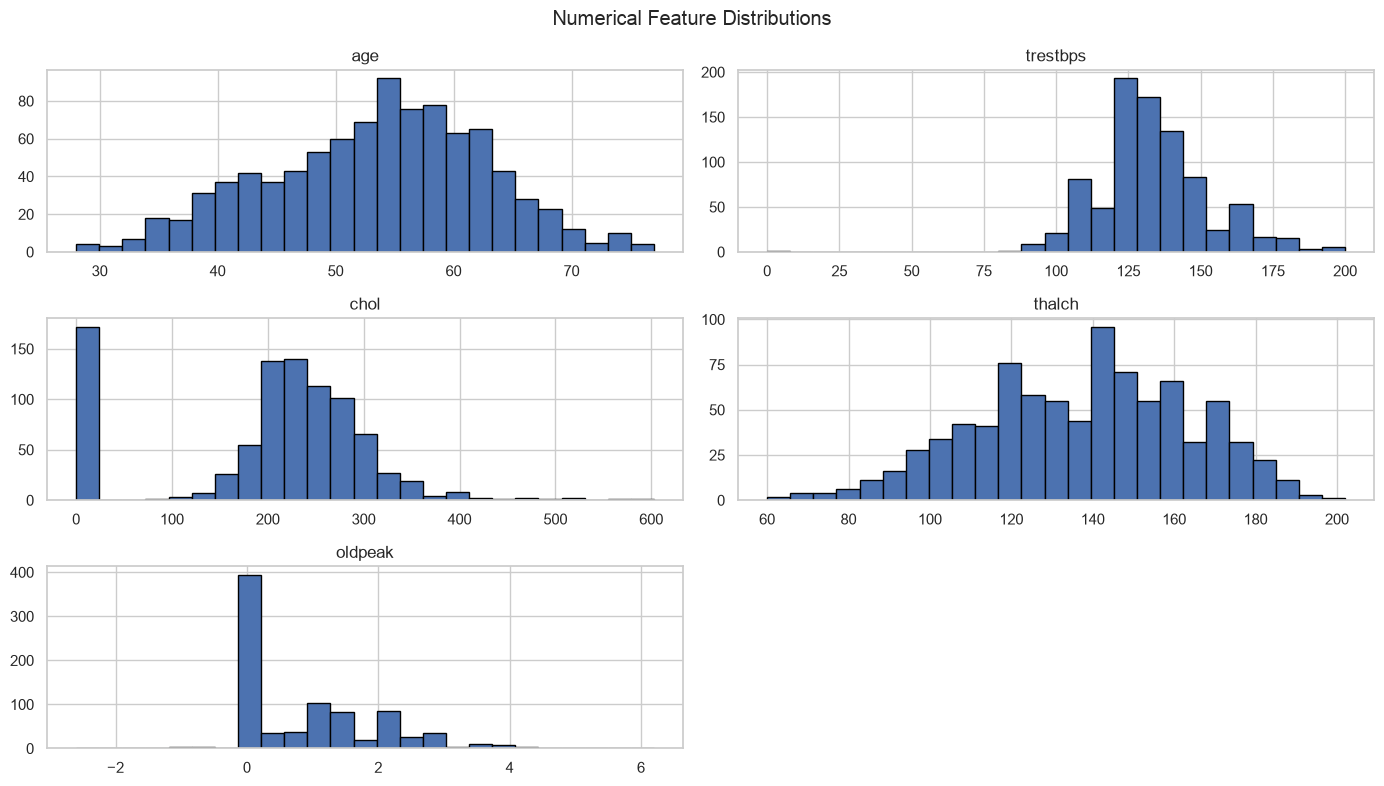

In [15]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalch",
    "oldpeak"
]

df[numerical_features].hist(
    figsize=(14, 8),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

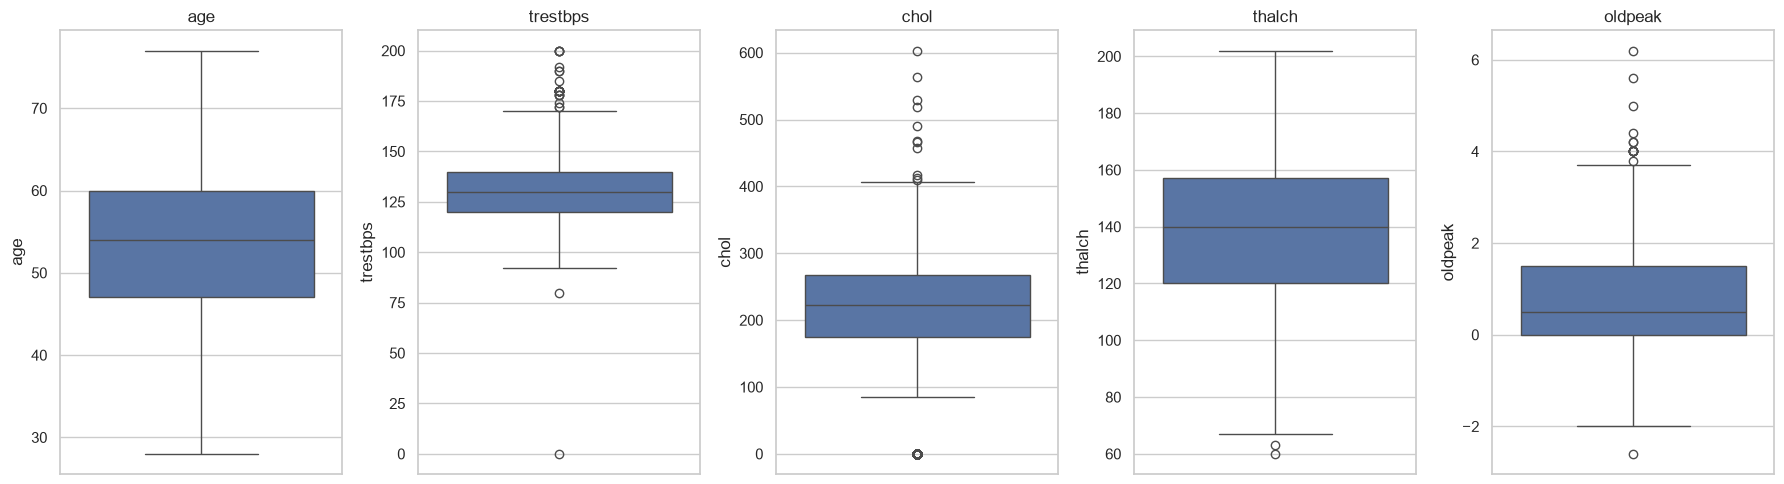

In [16]:
fig, axes = plt.subplots(
    1, 5,
    figsize=(18, 5)
)

for ax, column in zip(axes, numerical_features):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

In [17]:
plt.figure(figsize=(13, 10))

correlation = df.drop(
    columns=["hospital", "num"]
).corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

KeyError: "['hospital'] not found in axis"

<Figure size 1300x1000 with 0 Axes>